# The adaptive cut on HDBSCAN's tree

HDBSCAN builds a single-linkage tree on a density-adjusted distance (the mutual reachability
distance). It then simplifies the tree (branches with fewer than `min_cluster_size` points are
treated as points leaving their cluster) and selects clusters at different heights with its own
score, cluster stability. Points outside every selected cluster are noise (label -1).

The `hdbscan` package gives its tree as a scipy linkage matrix, so the adaptive cut can run on
it with any objective. This notebook compares the two on the same tree.

This notebook needs `pip install adaptive_cut hdbscan scikit-learn matplotlib`.

In [1]:
import hdbscan
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score as ari

import adaptive_cut as ac

In [2]:
def blobs(seed=0):
    """Three tight blobs (150 points each) next to two wide ones (300 each)."""
    rng = np.random.default_rng(seed)
    centers = np.array([[0, 0], [1.2, 0], [0.6, 1.0], [8, 0], [4, 7]])
    std = np.array([0.25, 0.25, 0.25, 1.6, 1.6])
    y = np.repeat(np.arange(5), [150, 150, 150, 300, 300])
    X = centers[y] + std[y, None] * rng.standard_normal((len(y), 2))
    return X, y


COLORS = np.array(
    [
        "#4269d0",
        "#efb118",
        "#ff725c",
        "#6cc5b0",
        "#3ca951",
        "#ff8ab7",
        "#a463f2",
        "#97bbf5",
        "#9c6b4e",
        "#9498a0",
    ]
)


def scatter(ax, X, labels, title):
    labels = np.asarray(labels)
    c = np.where(labels < 0, "#d0d0d0", COLORS[np.maximum(labels, 0) % len(COLORS)])
    ax.scatter(X[:, 0], X[:, 1], s=4, c=c, linewidths=0)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")

## HDBSCAN's tree as a scipy linkage matrix

In [3]:
X, y = blobs(seed=0)
clusterer = hdbscan.HDBSCAN(min_cluster_size=15).fit(X)
Z = clusterer.single_linkage_tree_.to_numpy()  # scipy linkage matrix
print(Z.shape, "balancedness", round(ac.balancedness(Z), 2))

(1049, 4) balancedness 0.19


## HDBSCAN's clusters against the adaptive cut of its tree

The adaptive cut uses the Gaussian BIC here. Its cut has no noise: every point is in a cluster.

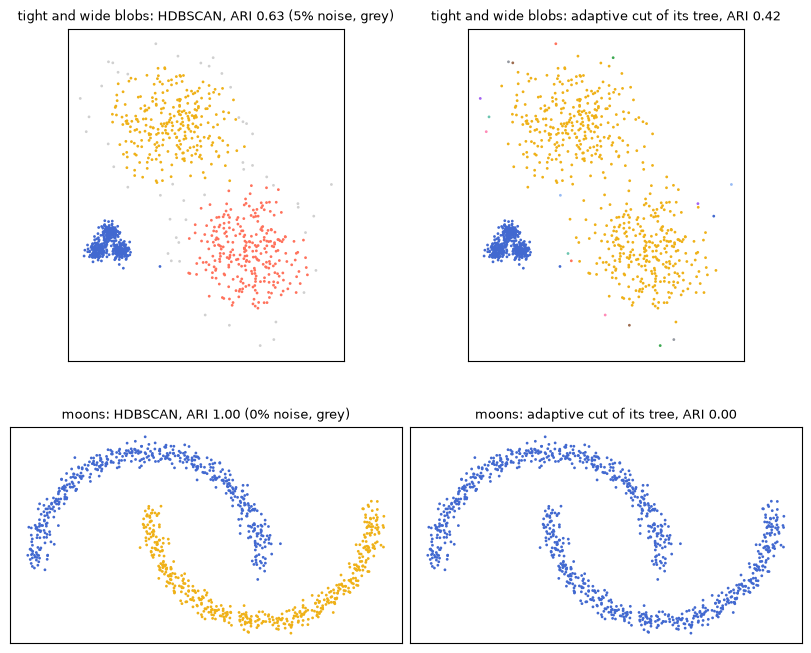

In [4]:
def compare(X, y, min_cluster_size=15, seed=0):
    clusterer = hdbscan.HDBSCAN(min_cluster_size=min_cluster_size).fit(X)
    Z = clusterer.single_linkage_tree_.to_numpy()
    res = ac.adaptive_cut(Z, ac.gaussian_scores(Z, X), T="auto", rng=seed)
    return clusterer.labels_, res.labels


data = {
    "tight and wide blobs": blobs(seed=0),
    "moons": make_moons(1000, noise=0.05, random_state=0),
}
fig, axes = plt.subplots(2, 2, figsize=(8, 7), layout="constrained")
for row, (name, (Xd, yd)) in zip(axes, data.items()):
    hdb, ada = compare(Xd, yd)
    noise = (hdb < 0).mean()
    scatter(row[0], Xd, hdb, f"{name}: HDBSCAN, ARI {ari(yd, hdb):.2f} ({noise:.0%} noise, grey)")
    scatter(row[1], Xd, ada, f"{name}: adaptive cut of its tree, ARI {ari(yd, ada):.2f}")

## What this shows

On both datasets HDBSCAN's own selection does better than the adaptive cut of its tree with the
Gaussian BIC:

- HDBSCAN already selects clusters at several heights of its tree, with a score made for
  density-based clusters, and it simplifies the tree first.
- The Gaussian BIC does not suit single-linkage trees: they chain points together, and their
  outliers merge last, so a Gaussian score cuts them badly. On moons the clusters are not
  Gaussian either.

The adaptive cut runs on HDBSCAN's tree with any objective, but with the Gaussian BIC it does
not improve on HDBSCAN. For clusters at different scales, a Ward tree (notebook 01) or a tree
over small clusters (notebook 04) suits the Gaussian score better.